In [7]:
import matplotlib.pyplot as plt
import numpy as np

import sys
sys.path.append('/Users/austindestcroix/Desktop/school_holders/projects/LOLX/calculations')

import track_structure as track

In [8]:
def fBirks(dEdx, kb, ly = 1):    
    return ly * dEdx/(1 + kb*dEdx)

def fBirks_Unitless(dEdx, kb):    
    return  1 /(1 + kb*dEdx)

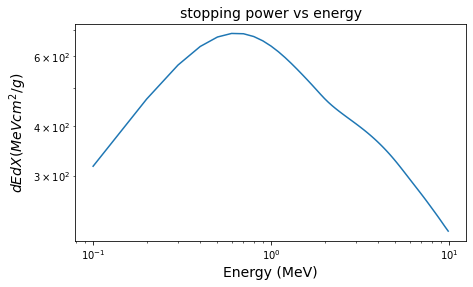

In [9]:
fig, ax = plt.subplots(1, 1, figsize = (7, 4))

E = np.arange(0.1, 10, 0.1)
alphaSP = track.alphadEdX_Ar() # MeV cm^2/g
ax.loglog(E, alphaSP(E))
ax.set_xlabel("Energy (MeV)", fontsize = 14)
ax.set_ylabel(r"$dEdX (MeV cm^2/g)$", fontsize = 14)
ax.set_title("stopping power vs energy", fontsize = 14)

plt.show()

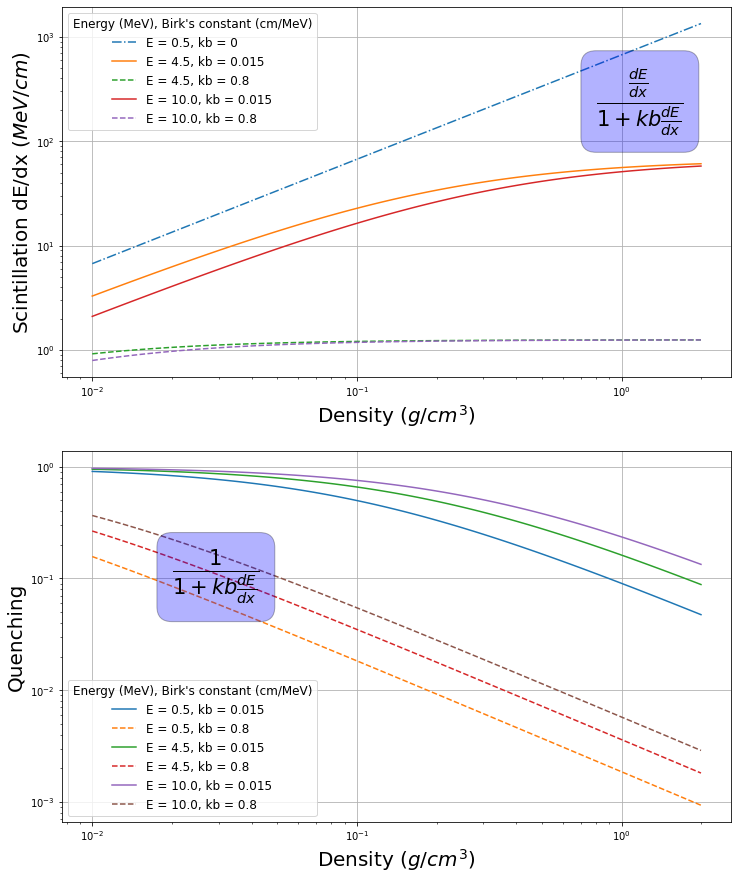

In [11]:
fig, axes = plt.subplots(2, 1, figsize = (12, 15))
ax = axes[0]
ax2= axes[1]

densities = np.logspace(-2, 0.3, 100)

energies = [0.5, 4.5, 10] # MeV
kbs = [0.0, 0.015, 0.8] # cm/MeV

markers = ["-.", "-", "--"]

for E in energies:
    alphaDEDX = alphaSP(E) * densities
    # this is dEdx at energy E (MeV) for different densities
    # MeV/cm
    for i, kb in enumerate(kbs):
        mark = markers[i]
        if E == 0.5 and kb == 0:
            ax.loglog(densities, fBirks(alphaDEDX, kb), label = "E = %0.1f, kb = %0.3g" % (E, kb), linestyle = mark)
        elif E == 0.5 and kb != 0:
            ax2.loglog(densities, fBirks_Unitless(alphaDEDX, kb), label = "E = %0.1f, kb = %0.3g" % (E, kb), linestyle = mark)
        elif kb > 0:
            ax.loglog(densities, fBirks(alphaDEDX, kb), label = "E = %0.1f, kb = %0.3g" % (E, kb), linestyle = mark)
            ax2.loglog(densities, fBirks_Unitless(alphaDEDX, kb), label = "E = %0.1f, kb = %0.3g" % (E, kb), linestyle = mark)


font = {'family': 'serif',
        'color':  'darkred',
        'weight': 'normal',
        'size': 16,
        }
lSize = 20
ax.text(0.8, 200, r'$\frac{\frac{dE}{dx}}{1 + kb \frac{dE}{dx}}$', fontsize = 30, bbox = dict(facecolor='blue', alpha=0.3, boxstyle='round,pad=0.5'))
ax.set_ylabel(r"Scintillation dE/dx $(MeV/cm)$", fontsize = lSize)
ax.set_xlabel(r"Density $(g/cm^3)$", fontsize = lSize)
ax.legend(title = "Energy (MeV), Birk's constant (cm/MeV)", title_fontsize = 12, fontsize = 12)
ax.grid()

ax2.text(0.02, 0.1, r'$\frac{1}{1 + kb \frac{dE}{dx}}$', fontsize = 30, bbox = dict(facecolor='blue', alpha=0.3, boxstyle='round,pad=0.5'))
ax2.set_ylabel(r"Quenching", fontsize = lSize)
ax2.set_xlabel(r"Density $(g/cm^3)$", fontsize = lSize)
ax2.legend(title = "Energy (MeV), Birk's constant (cm/MeV)", title_fontsize = 12, fontsize = 12)
ax2.grid()


plt.show()